# Day 4 – Delivery Time Prediction

## Objective
Build regression models to predict delivery time in minutes. This notebook covers EDA, feature engineering, train/test split, a baseline, Ridge, Lasso, Random Forest, cross-validation, overfitting checks, MAE, RMSE, R², feature importance, and business interpretation.

The notebook uses the project's CSV files in `data/raw/`. Results are calculated from your actual data when you run the notebook.

## 1. Import libraries

In [5]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the data
When this notebook is inside `notebooks/`, the raw files should be in `../data/raw/`. The second path supports running the notebook from the project root.

In [6]:
candidate_dirs = [Path("../data/raw"), Path("data/raw")]
DATA_DIR = next((p for p in candidate_dirs if p.exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Cannot find data/raw. Open this notebook from the notebooks folder or update DATA_DIR.")

file_names = ["customers.csv", "deliveries.csv", "drivers.csv", "orders.csv", "payments.csv", "restaurants.csv"]
tables = {}
for filename in file_names:
    path = DATA_DIR / filename
    if path.exists():
        tables[path.stem] = pd.read_csv(path)
        print(f"{filename}: {tables[path.stem].shape}")
    else:
        print(f"Skipping missing file: {filename}")
if not tables:
    raise FileNotFoundError(f"No CSV files found in {DATA_DIR.resolve()}")

customers.csv: (500, 5)
deliveries.csv: (9004, 7)
drivers.csv: (150, 5)
orders.csv: (10000, 9)
payments.csv: (10000, 5)
restaurants.csv: (100, 6)


## 3. Inspect tables and column names
This check helps identify the fields available in your version of the dataset.

In [7]:
for name, frame in tables.items():
    print(f"\n{name.upper()} — {frame.shape}")
    print(frame.columns.tolist())


CUSTOMERS — (500, 5)
['customer_id', 'age', 'gender', 'city', 'signup_date']

DELIVERIES — (9004, 7)
['delivery_id', 'order_id', 'driver_id', 'distance_km', 'traffic_level', 'weather', 'delivery_time_minutes']

DRIVERS — (150, 5)
['driver_id', 'vehicle_type', 'driver_rating', 'experience_months', 'city']

ORDERS — (10000, 9)
['order_id', 'customer_id', 'restaurant_id', 'order_timestamp', 'order_amount', 'num_items', 'order_status', 'order_hour', 'order_date']

PAYMENTS — (10000, 5)
['payment_id', 'order_id', 'payment_amount', 'payment_method', 'payment_status']

RESTAURANTS — (100, 6)
['restaurant_id', 'restaurant_name', 'cuisine', 'city', 'restaurant_rating', 'average_prep_time_minutes']


## 4. Build a modelling table
Column names are standardized to lowercase snake_case. We choose a table containing a delivery duration or suitable start/end timestamps, then join related tables when a shared ID is available. Payments are not joined because multiple payment rows can duplicate orders and are not needed for delivery-time prediction.

In [8]:
def standardize_columns(frame):
    frame = frame.copy()
    frame.columns = (frame.columns.astype(str).str.strip().str.lower()
                     .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
    return frame

tables = {name: standardize_columns(frame) for name, frame in tables.items()}

TARGET_ALIASES = [
    "delivery_time_minutes", "delivery_duration_minutes", "delivery_duration_mins",
    "delivery_duration", "delivery_time_mins", "delivery_time"
]
START_ALIASES = [
    "order_time", "order_timestamp", "created_at", "order_created_at",
    "placed_at", "request_time", "order_date_time", "order_datetime"
]
END_ALIASES = [
    "delivered_time", "delivered_at", "actual_delivery_time",
    "delivery_completed_at", "completed_at"
]

def find_column(frame, candidates):
    return next((c for c in candidates if c in frame.columns), None)

def target_possible(frame):
    return (find_column(frame, TARGET_ALIASES) is not None or
            (find_column(frame, START_ALIASES) is not None and
             find_column(frame, END_ALIASES) is not None))

base_name = next((n for n in ["deliveries", "orders"]
                  if n in tables and target_possible(tables[n])), None)
if base_name is None:
    base_name = next((n for n, f in tables.items() if target_possible(f)), None)
if base_name is None:
    raise ValueError("Could not find a delivery duration column or a suitable start/end timestamp pair. Review Section 3 and update the alias lists.")

model_df = tables[base_name].copy()
print("Starting table:", base_name, model_df.shape)

join_keys = {
    "orders": ["order_id"], "deliveries": ["order_id"],
    "customers": ["customer_id", "user_id"],
    "restaurants": ["restaurant_id"], "drivers": ["driver_id"]
}
for name in ["orders", "deliveries", "customers", "restaurants", "drivers"]:
    if name == base_name or name not in tables:
        continue
    right = tables[name].copy()
    candidates = join_keys.get(name, ["order_id"])
    key = next((k for k in candidates if k in model_df.columns and k in right.columns), None)
    if key is None and "order_id" in model_df.columns and "order_id" in right.columns:
        key = "order_id"
    if key is None:
        print(f"Skipped {name}: no shared join key.")
        continue
    if right[key].duplicated().any():
        print(f"Note: {name}.{key} has duplicate keys; keeping the first row per key to prevent row multiplication.")
        right = right.drop_duplicates(subset=[key], keep="first")
    model_df = model_df.merge(right, on=key, how="left", suffixes=("", f"_{name}"))
    print(f"Joined {name} on {key}: {model_df.shape}")

print("Modelling table:", model_df.shape)
display(model_df.head())

Starting table: deliveries (9004, 7)
Joined orders on order_id: (9004, 15)
Joined customers on customer_id: (9004, 19)
Joined restaurants on restaurant_id: (9004, 24)
Joined drivers on driver_id: (9004, 28)
Modelling table: (9004, 28)


,delivery_id,order_id,driver_id,distance_km,traffic_level,weather,delivery_time_minutes,customer_id,restaurant_id,order_timestamp,order_amount,num_items,order_status,order_hour,order_date,age,gender,city,signup_date,restaurant_name,cuisine,city_restaurants,restaurant_rating,average_prep_time_minutes,vehicle_type,driver_rating,experience_months,city_drivers
0,1,1,63,3.32,Medium,Cloudy,32,485,10,2024-01-28 07:24:00,1748.55,6,Completed,7,2024-01-28,40,Male,Mumbai,2023-05-18,Restaurant_010,Indian,Delhi,2.9,20,Scooter,4.9,117,Mumbai
1,2,2,114,8.22,High,Rainy,66,276,13,2025-10-22 18:26:00,912.87,9,Completed,18,2025-10-22,41,Male,Bengaluru,2023-09-13,Restaurant_013,Desserts,Bengaluru,4.0,24,Scooter,2.7,27,Mumbai
2,3,3,34,4.29,Medium,Rainy,45,71,20,2024-01-15 01:04:00,1071.24,2,Completed,1,2024-01-15,56,Female,Bengaluru,2022-10-04,Restaurant_020,Desserts,Delhi,3.4,21,Scooter,3.2,92,Mumbai
3,4,4,58,6.69,Medium,Clear,46,183,77,2022-01-18 14:35:00,712.16,10,Completed,14,2022-01-18,41,Female,Bengaluru,2024-06-04,Restaurant_077,Chinese,Delhi,2.7,25,Scooter,3.5,111,Bengaluru
4,5,5,25,17.31,Medium,Clear,60,122,44,2025-06-29 12:41:00,77.87,4,Completed,12,2025-06-29,50,Male,Bengaluru,2025-10-24,Restaurant_044,Italian,Hyderabad,2.6,15,Scooter,4.5,100,Hyderabad


## 5. Create the target
We use a duration column if available. Otherwise, we calculate minutes between order placement and delivery completion. Rows with missing or non-positive durations are excluded because they are not valid delivery durations. Unusual long durations are inspected in EDA rather than automatically removed.

In [9]:
target_col = find_column(model_df, TARGET_ALIASES)
if target_col:
    model_df["delivery_time_minutes"] = pd.to_numeric(model_df[target_col], errors="coerce")
    target_source = f"existing column '{target_col}'"
else:
    start_col = find_column(model_df, START_ALIASES)
    end_col = find_column(model_df, END_ALIASES)
    if start_col is None or end_col is None:
        raise ValueError("No usable duration column or timestamp pair found. Update the alias lists in Section 4.")
    start_dt = pd.to_datetime(model_df[start_col], errors="coerce")
    end_dt = pd.to_datetime(model_df[end_col], errors="coerce")
    model_df["delivery_time_minutes"] = (end_dt - start_dt).dt.total_seconds() / 60
    target_source = f"calculated from '{start_col}' and '{end_col}'"

model_df["delivery_time_minutes"] = pd.to_numeric(model_df["delivery_time_minutes"], errors="coerce")
print("Target source:", target_source)
print("Rows before validation:", len(model_df))
model_df = model_df.loc[
    model_df["delivery_time_minutes"].notna() & (model_df["delivery_time_minutes"] > 0)
].copy()
print("Rows with valid delivery time:", len(model_df))
display(model_df["delivery_time_minutes"].describe().to_frame())

Target source: existing column 'delivery_time_minutes'
Rows before validation: 9004
Rows with valid delivery time: 9004


,delivery_time_minutes
count,9004.000000
mean,60.333407
std,16.981323
min,10.000000
25%,48.000000
50%,60.000000
75%,73.000000
max,120.000000


## 6. EDA: target distribution and outliers
Outliers can be real operational events, so this notebook flags them for review instead of silently deleting them.

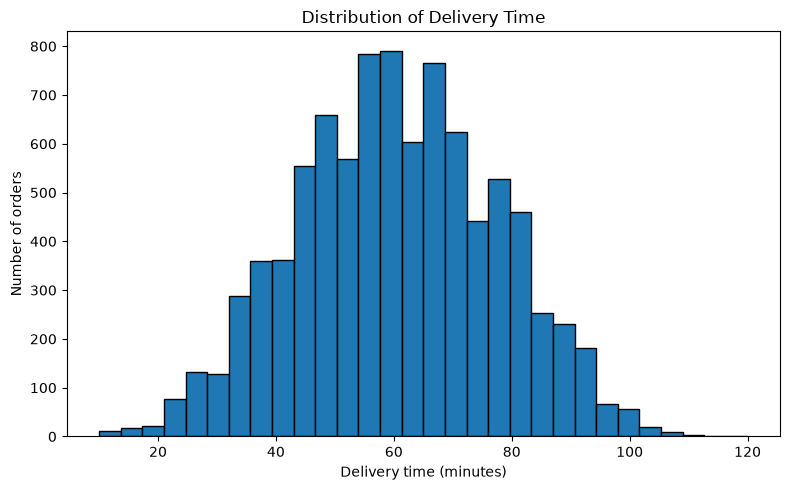

IQR bounds: 10.50 to 110.50 minutes
Potential outliers: 8 (0.09%)


,delivery_time_minutes
7720,120
2132,114
6079,114
2159,112
5443,112
4452,111
1941,10
5796,10


In [10]:
plt.figure(figsize=(8, 5))
plt.hist(model_df["delivery_time_minutes"], bins=30, edgecolor="black")
plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Number of orders")
plt.tight_layout()
plt.show()

q1 = model_df["delivery_time_minutes"].quantile(0.25)
q3 = model_df["delivery_time_minutes"].quantile(0.75)
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier_mask = model_df["delivery_time_minutes"].lt(lower_bound) | model_df["delivery_time_minutes"].gt(upper_bound)
print(f"IQR bounds: {lower_bound:.2f} to {upper_bound:.2f} minutes")
print(f"Potential outliers: {outlier_mask.sum():,} ({outlier_mask.mean()*100:.2f}%)")
display(model_df.loc[outlier_mask, ["delivery_time_minutes"]].sort_values("delivery_time_minutes", ascending=False).head(10))

### 6.1 Correlation with numeric features
Correlation shows association, not causation.

,correlation
driver_rating,-0.011728
driver_id,-0.011518
customer_id,-0.005645
order_hour,-0.002432
order_amount,-0.000750
age,0.003305
num_items,0.004140
delivery_id,0.006942
order_id,0.006950
experience_months,0.014494


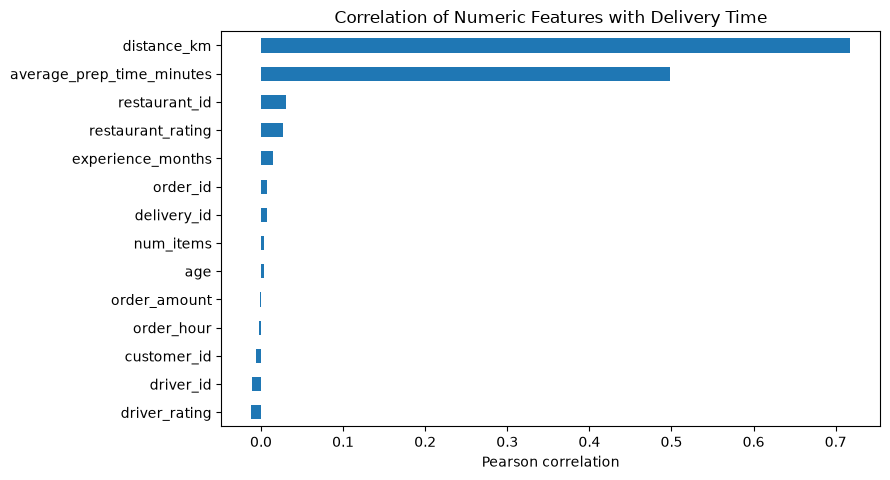

In [11]:
numeric_df = model_df.select_dtypes(include=np.number)
if numeric_df.shape[1] >= 2 and "delivery_time_minutes" in numeric_df.columns:
    correlations = numeric_df.corr(numeric_only=True)["delivery_time_minutes"].drop("delivery_time_minutes").dropna().sort_values()
    display(correlations.to_frame("correlation"))
    if not correlations.empty:
        plt.figure(figsize=(9, max(4, len(correlations) * 0.35)))
        correlations.plot(kind="barh")
        plt.title("Correlation of Numeric Features with Delivery Time")
        plt.xlabel("Pearson correlation")
        plt.tight_layout()
        plt.show()
else:
    print("Not enough numeric columns for correlation analysis.")

### 6.2 Scatter plots
We plot a few common numeric predictors if they exist in the dataset.

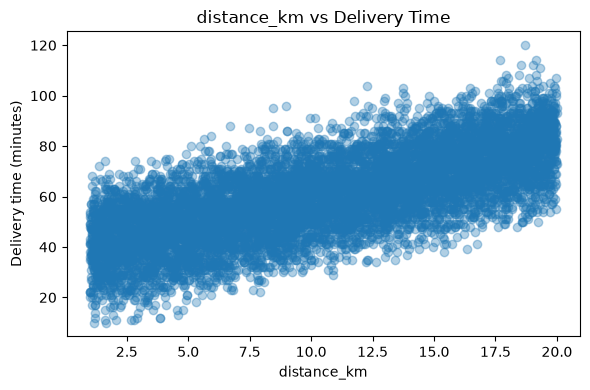

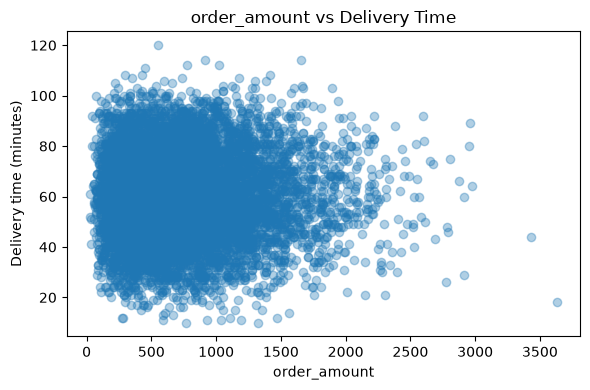

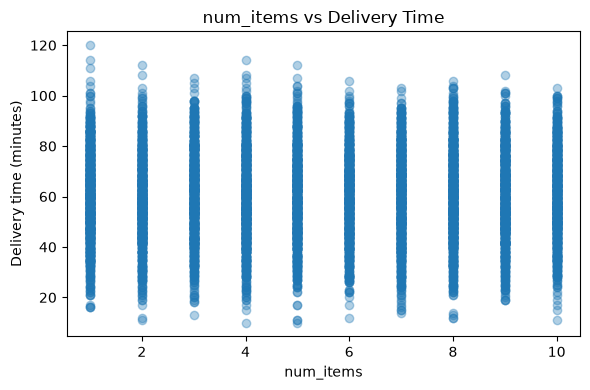

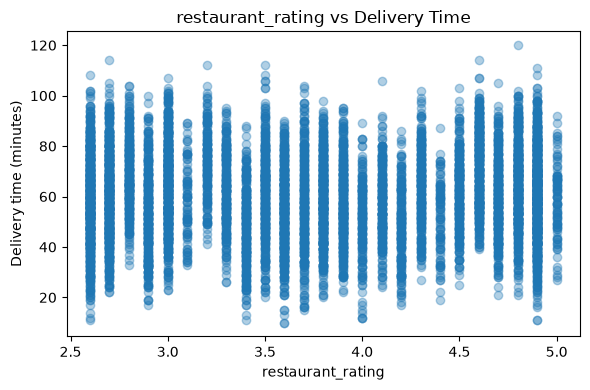

In [12]:
scatter_candidates = [
    "delivery_distance_km", "distance_km", "distance",
    "order_amount", "order_value", "total_amount",
    "num_items", "number_of_items", "item_count",
    "preparation_time_minutes", "prep_time_minutes", "avg_prep_time_mins",
    "restaurant_rating", "rating"
]
scatter_cols = []
for col in scatter_candidates:
    if col in model_df.columns and pd.api.types.is_numeric_dtype(model_df[col]) and col not in scatter_cols:
        scatter_cols.append(col)
    if len(scatter_cols) >= 4:
        break

if scatter_cols:
    for col in scatter_cols:
        plot_data = model_df[[col, "delivery_time_minutes"]].dropna()
        if not plot_data.empty:
            plt.figure(figsize=(6, 4))
            plt.scatter(plot_data[col], plot_data["delivery_time_minutes"], alpha=0.35)
            plt.title(f"{col} vs Delivery Time")
            plt.xlabel(col)
            plt.ylabel("Delivery time (minutes)")
            plt.tight_layout()
            plt.show()
else:
    print("No common numeric predictor columns were found for scatter plots.")

## 7. Feature engineering and leakage prevention
We create hour, day-of-week, and weekend features from an order timestamp when possible. We exclude direct target fields, delivery-completion timestamps, pickup timestamps, and identifiers from the predictors because they would not be appropriate inputs for a delivery-time prediction made when an order is placed.

In [13]:
order_time_col = find_column(model_df, START_ALIASES)
if order_time_col:
    order_dt = pd.to_datetime(model_df[order_time_col], errors="coerce")
    model_df["order_hour"] = order_dt.dt.hour
    model_df["order_day_of_week"] = order_dt.dt.dayofweek
    model_df["is_weekend"] = order_dt.dt.dayofweek.isin([5, 6]).astype("Int64")
    print("Created time features from:", order_time_col)
else:
    print("No order timestamp found; time features were skipped.")

leakage_tokens = [
    "delivered", "delivery_completed", "actual_delivery", "delivery_duration",
    "delivery_time", "pickup_time", "picked_up", "arrival_time", "completed_at"
]
drop_cols = {"delivery_time_minutes"}
for col in model_df.columns:
    if col == "delivery_time_minutes":
        continue
    if any(token in col for token in leakage_tokens):
        drop_cols.add(col)
if order_time_col:
    drop_cols.discard(order_time_col)

for col in model_df.columns:
    if col != "delivery_time_minutes" and (
        col.endswith("_id") or col in {"id", "order_id", "customer_id", "restaurant_id", "driver_id"}
    ):
        drop_cols.add(col)

X = model_df.drop(columns=[c for c in drop_cols if c in model_df.columns], errors="ignore").copy()
y = model_df["delivery_time_minutes"].copy()

empty_cols = [c for c in X.columns if X[c].isna().all()]
constant_cols = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
X = X.drop(columns=list(set(empty_cols + constant_cols)), errors="ignore")

for col in X.select_dtypes(include=["datetime", "datetimetz"]).columns:
    X[col] = X[col].astype(str)
for col in X.select_dtypes(include="object").columns:
    converted = pd.to_numeric(X[col], errors="coerce")
    nonmissing = X[col].notna().sum()
    if nonmissing and converted.notna().sum() / nonmissing >= 0.95:
        X[col] = converted

print("Rows:", len(X), "| predictor columns:", X.shape[1])
print("Numeric predictors:", X.select_dtypes(include=np.number).columns.tolist())
print("Categorical predictors:", X.select_dtypes(exclude=np.number).columns.tolist())
if X.shape[1] == 0:
    raise ValueError("No usable predictors remain. Review the column names and leakage rules.")
display(X.head())

/tmp/ipykernel_45967/3566175186.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  model_df["order_day_of_week"] = order_dt.dt.dayofweek
/tmp/ipykernel_45967/3566175186.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  model_df["is_weekend"] = order_dt.dt.dayofweek.isin([5, 6]).astype("Int64")
/tmp/ipykernel_45967/3566175186.py:39: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X.select_dtypes(include="ob

Created time features from: order_timestamp
Rows: 9004 | predictor columns: 23
Numeric predictors: ['distance_km', 'order_amount', 'num_items', 'order_hour', 'age', 'restaurant_rating', 'average_prep_time_minutes', 'driver_rating', 'experience_months', 'order_day_of_week', 'is_weekend']
Categorical predictors: ['traffic_level', 'weather', 'order_timestamp', 'order_date', 'gender', 'city', 'signup_date', 'restaurant_name', 'cuisine', 'city_restaurants', 'vehicle_type', 'city_drivers']


,distance_km,traffic_level,weather,order_timestamp,order_amount,num_items,order_hour,order_date,age,gender,city,signup_date,restaurant_name,cuisine,city_restaurants,restaurant_rating,average_prep_time_minutes,vehicle_type,driver_rating,experience_months,city_drivers,order_day_of_week,is_weekend
0,3.32,Medium,Cloudy,2024-01-28 07:24:00,1748.55,6,7,2024-01-28,40,Male,Mumbai,2023-05-18,Restaurant_010,Indian,Delhi,2.9,20,Scooter,4.9,117,Mumbai,6,1
1,8.22,High,Rainy,2025-10-22 18:26:00,912.87,9,18,2025-10-22,41,Male,Bengaluru,2023-09-13,Restaurant_013,Desserts,Bengaluru,4.0,24,Scooter,2.7,27,Mumbai,2,0
2,4.29,Medium,Rainy,2024-01-15 01:04:00,1071.24,2,1,2024-01-15,56,Female,Bengaluru,2022-10-04,Restaurant_020,Desserts,Delhi,3.4,21,Scooter,3.2,92,Mumbai,0,0
3,6.69,Medium,Clear,2022-01-18 14:35:00,712.16,10,14,2022-01-18,41,Female,Bengaluru,2024-06-04,Restaurant_077,Chinese,Delhi,2.7,25,Scooter,3.5,111,Bengaluru,1,0
4,17.31,Medium,Clear,2025-06-29 12:41:00,77.87,4,12,2025-06-29,50,Male,Bengaluru,2025-10-24,Restaurant_044,Italian,Hyderabad,2.6,15,Scooter,4.5,100,Hyderabad,6,1


## 8. Train/test split and preprocessing
The test set is held back for final evaluation. Missing numeric values are filled with the training median; missing categorical values use the most common value. Categorical columns are one-hot encoded and numeric columns are scaled.

In [14]:
if len(X) < 10:
    raise ValueError("Too few valid rows to evaluate regression models reliably.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
], remainder="drop")

print(f"Train rows: {len(X_train):,}; test rows: {len(X_test):,}")
print(f"Numeric predictors: {len(numeric_features)}; categorical predictors: {len(categorical_features)}")

Train rows: 7,203; test rows: 1,801
Numeric predictors: 11; categorical predictors: 12


## 9. Train the regression models
The baseline predicts the training-set average. Ridge and Lasso are regularized linear models. Random Forest combines many decision trees and can learn non-linear patterns.

In [15]:
estimators = {
    "Baseline (training mean)": DummyRegressor(strategy="mean"),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01, max_iter=10000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(
        n_estimators=250, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
    )
}
pipelines = {}
for name, estimator in estimators.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    print("Trained:", name)

Trained: Baseline (training mean)
Trained: Ridge Regression
Trained: Lasso Regression
Trained: Random Forest


## 10. Model evaluation
- **MAE:** average absolute error in minutes; lower is better.
- **RMSE:** penalizes large errors more strongly; lower is better.
- **R²:** compares model predictions with a mean-based reference; closer to 1 is generally better, and negative values indicate poor performance.

In [16]:
def evaluate(actual, predicted):
    return {
        "MAE (minutes)": mean_absolute_error(actual, predicted),
        "RMSE (minutes)": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

predictions = {}
rows = []
for name, pipe in pipelines.items():
    pred = pipe.predict(X_test)
    predictions[name] = pred
    rows.append({"Model": name, **evaluate(y_test, pred)})

results = pd.DataFrame(rows).sort_values("MAE (minutes)").reset_index(drop=True)
display(results.round(3))
best_model_name = results.loc[0, "Model"]
best_model = pipelines[best_model_name]
best_predictions = predictions[best_model_name]
print("Best model by test MAE:", best_model_name)

,Model,MAE (minutes),RMSE (minutes),R2
0,Lasso Regression,4.141,5.210,0.908
1,Random Forest,4.448,5.592,0.894
2,Ridge Regression,4.463,5.635,0.893
3,Baseline (training mean),13.988,17.210,-0.000


Best model by test MAE: Lasso Regression


## 11. Check for overfitting
A large gap between training and test results can indicate overfitting.

In [17]:
overfit_rows = []
for name, pipe in pipelines.items():
    train_pred = pipe.predict(X_train)
    test_pred = pipe.predict(X_test)
    overfit_rows.append({
        "Model": name,
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Test MAE": mean_absolute_error(y_test, test_pred),
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred)
    })
overfit_results = pd.DataFrame(overfit_rows).sort_values("Test MAE").reset_index(drop=True)
display(overfit_results.round(3))

,Model,Train MAE,Test MAE,Train R2,Test R2
0,Lasso Regression,3.980,4.141,0.912,0.908
1,Random Forest,1.858,4.448,0.979,0.894
2,Ridge Regression,1.730,4.463,0.983,0.893
3,Baseline (training mean),13.757,13.988,0.000,-0.000


## 12. Cross-validation
Cross-validation rotates the validation fold within the training data. It gives a more stable performance estimate. The held-out test set is not used in this step.

In [18]:
n_splits = min(5, len(X_train))
if n_splits >= 2:
    cv = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    cv_rows = []
    for name, pipe in pipelines.items():
        scores = cross_validate(
            pipe, X_train, y_train, cv=cv,
            scoring="neg_mean_absolute_error", n_jobs=1, error_score="raise"
        )
        fold_mae = -scores["test_score"]
        cv_rows.append({
            "Model": name,
            "Mean CV MAE": fold_mae.mean(),
            "Std CV MAE": fold_mae.std()
        })
    cv_results = pd.DataFrame(cv_rows).sort_values("Mean CV MAE").reset_index(drop=True)
    display(cv_results.round(3))
else:
    print("Not enough rows for cross-validation.")

,Model,Mean CV MAE,Std CV MAE
0,Lasso Regression,4.003,0.095
1,Ridge Regression,4.349,0.103
2,Random Forest,4.421,0.121
3,Baseline (training mean),13.757,0.244


## 13. Random Forest feature importance
Permutation importance measures how much test-set error increases when one input feature is shuffled. Higher values indicate that the model relied more on that feature. This does not prove cause and effect.

/home/nineleaps/Desktop/ML_Assignment/.venv/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/nineleaps/Desktop/ML_Assignment/.venv/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/nineleaps/Desktop/ML_Assignment/.venv/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/nine

,Feature,Importance (MAE increase),Std
0,distance_km,9.9067,0.1187
1,average_prep_time_minutes,6.1856,0.1062
2,traffic_level,2.8212,0.0934
3,weather,1.5245,0.0741
4,age,0.0148,0.0020
5,order_amount,0.0115,0.0051
6,city,0.0063,0.0028
7,city_restaurants,0.0061,0.0041
8,order_hour,0.0058,0.0041
9,driver_rating,0.0049,0.0094


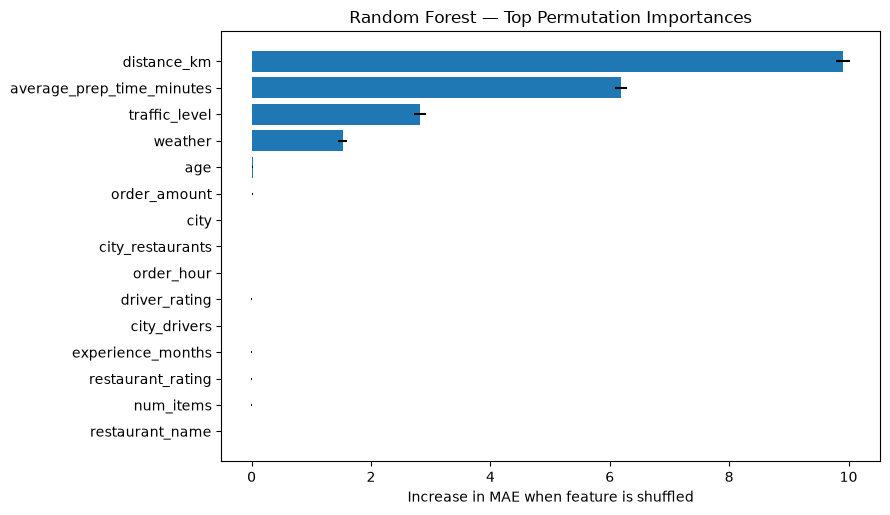

In [19]:
rf_pipe = pipelines["Random Forest"]
perm = permutation_importance(
    rf_pipe, X_test, y_test, scoring="neg_mean_absolute_error",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)
importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance (MAE increase)": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values("Importance (MAE increase)", ascending=False).reset_index(drop=True)
display(importance.head(15).round(4))

top = importance.head(15).sort_values("Importance (MAE increase)")
plt.figure(figsize=(9, max(4, len(top) * 0.35)))
plt.barh(top["Feature"], top["Importance (MAE increase)"], xerr=top["Std"])
plt.title("Random Forest — Top Permutation Importances")
plt.xlabel("Increase in MAE when feature is shuffled")
plt.tight_layout()
plt.show()

## 14. Actual vs predicted
Points closer to the diagonal line show more accurate predictions.

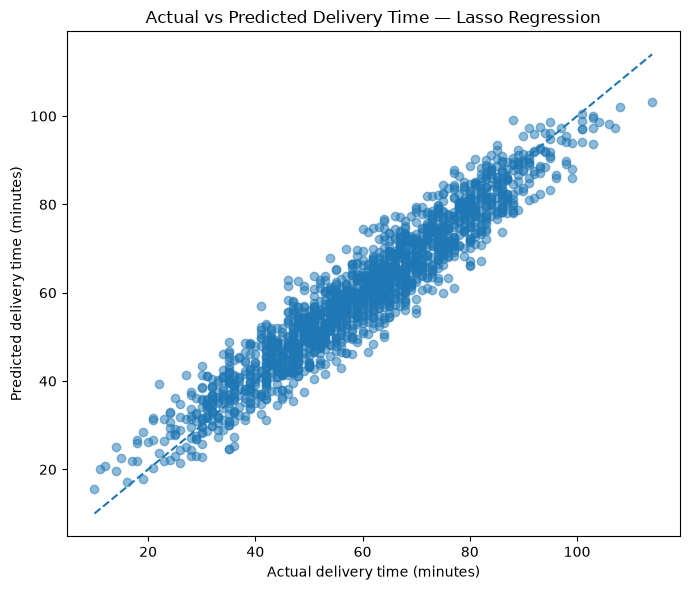

In [20]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.5)
plot_min = min(float(y_test.min()), float(np.min(best_predictions)))
plot_max = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([plot_min, plot_max], [plot_min, plot_max], linestyle="--")
plt.title(f"Actual vs Predicted Delivery Time — {best_model_name}")
plt.xlabel("Actual delivery time (minutes)")
plt.ylabel("Predicted delivery time (minutes)")
plt.tight_layout()
plt.show()

## 15. Review prediction errors

In [21]:
prediction_check = pd.DataFrame({
    "Actual delivery time (minutes)": y_test,
    "Predicted delivery time (minutes)": best_predictions
})
prediction_check["Error (predicted - actual)"] = (
    prediction_check["Predicted delivery time (minutes)"] -
    prediction_check["Actual delivery time (minutes)"]
)
prediction_check["Absolute error (minutes)"] = prediction_check["Error (predicted - actual)"].abs()
display(prediction_check.head(15).round(2))

,Actual delivery time (minutes),Predicted delivery time (minutes),Error (predicted - actual),Absolute error (minutes)
8718,79,76.56,-2.44,2.44
248,32,38.68,6.68,6.68
6142,52,50.83,-1.17,1.17
1421,52,48.70,-3.30,3.30
7021,52,55.38,3.38,3.38
5925,41,52.25,11.25,11.25
4038,46,46.15,0.15,0.15
4664,47,51.83,4.83,4.83
7467,60,69.50,9.50,9.50
4794,39,39.85,0.85,0.85


## 16. Final recommendation and business interpretation
The recommended model is selected by the lowest test MAE. Consider MAE, RMSE, R², cross-validation, and the train/test gap together. A simpler model can be preferable if its accuracy is close to a complex model.

Business interpretation should use the actual metrics printed below. Lower MAE means the estimated delivery time is closer to the true time on average. RMSE highlights large mistakes, and R² summarizes how well the model explains variation in delivery time.

In [22]:
best_row = results.iloc[0]
print("FINAL MODEL SUMMARY")
print("-" * 45)
print(f"Recommended model by test MAE: {best_row['Model']}")
print(f"Test MAE:  {best_row['MAE (minutes)']:.2f} minutes")
print(f"Test RMSE: {best_row['RMSE (minutes)']:.2f} minutes")
print(f"Test R²:   {best_row['R2']:.3f}")
print(
    f"On the held-out test data, the recommended model's prediction differs from actual "
    f"delivery time by about {best_row['MAE (minutes)']:.2f} minutes on average. "
    "Review cross-validation and train/test results before choosing it for real use."
)
print("\nLimitations:")
print("- Results depend on data quality and the predictors available.")
print("- Correlation and feature importance do not prove causation.")
print("- Traffic, weather, or distance may be important if available in future data.")
print("- Test the model on newer orders before operational use.")

FINAL MODEL SUMMARY
---------------------------------------------
Recommended model by test MAE: Lasso Regression
Test MAE:  4.14 minutes
Test RMSE: 5.21 minutes
Test R²:   0.908
On the held-out test data, the recommended model's prediction differs from actual delivery time by about 4.14 minutes on average. Review cross-validation and train/test results before choosing it for real use.

Limitations:
- Results depend on data quality and the predictors available.
- Correlation and feature importance do not prove causation.
- Traffic, weather, or distance may be important if available in future data.
- Test the model on newer orders before operational use.


## 17. Save outputs
The feature-engineered data and model comparison are saved under `data/processed/`. The raw CSV files are not modified.

In [23]:
output_dir = DATA_DIR.parent / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

feature_engineered = X.copy()
feature_engineered["delivery_time_minutes"] = y
feature_engineered.to_csv(output_dir / "delivery_time_feature_engineered.csv", index=False)
results.to_csv(output_dir / "delivery_time_model_comparison.csv", index=False)

print("Saved:")
print(output_dir / "delivery_time_feature_engineered.csv")
print(output_dir / "delivery_time_model_comparison.csv")

Saved:
../data/processed/delivery_time_feature_engineered.csv
../data/processed/delivery_time_model_comparison.csv


## Conclusion

This notebook explored delivery-time patterns, created time-based features where possible, and compared a baseline, Ridge, Lasso, and Random Forest regression. Models were evaluated with MAE, RMSE, R², cross-validation, and a train/test comparison. Random Forest permutation importance and an actual-versus-predicted chart were also included.

Use the metrics generated from the real data to make the final recommendation. Before deployment, test on future orders and ensure every predictor is available when a delivery-time prediction would be made.